# Netflix Content Recommendation System

**Goal:** Build a content-based recommendation system that suggests similar Netflix titles using genres, categories and other content attributes.

**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-Learn

## 1. Import Libraries
Importing the libraries used for data handling, visualisation, text feature extraction and similarity calculation.

In [1]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Read & Analyze The csv file

In [2]:
df = pd.read_csv('Dataset.csv')
df.head()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [3]:
df.tail()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
8785,s8797,TV Show,Yunus Emre,Not Given,Turkey,1/17/2017,2016,TV-PG,2 Seasons,"International TV Shows, TV Dramas"
8786,s8798,TV Show,Zak Storm,Not Given,United States,9/13/2018,2016,TV-Y7,3 Seasons,Kids' TV
8787,s8801,TV Show,Zindagi Gulzar Hai,Not Given,Pakistan,12/15/2016,2012,TV-PG,1 Season,"International TV Shows, Romantic TV Shows, TV ..."
8788,s8784,TV Show,Yoko,Not Given,Pakistan,6/23/2018,2016,TV-Y,1 Season,Kids' TV
8789,s8786,TV Show,YOM,Not Given,Pakistan,06/07/2018,2016,TV-Y7,1 Season,Kids' TV


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8790 non-null   str  
 1   type          8790 non-null   str  
 2   title         8790 non-null   str  
 3   director      8790 non-null   str  
 4   country       8790 non-null   str  
 5   date_added    8790 non-null   str  
 6   release_year  8790 non-null   int64
 7   rating        8790 non-null   str  
 8   duration      8790 non-null   str  
 9   listed_in     8790 non-null   str  
dtypes: int64(1), str(9)
memory usage: 1.6 MB


## 3. Removing the unnecessary columns and details

In [5]:
df_clean = df.drop(columns = ['show_id','date_added','release_year', 'duration'] )

In [6]:
df_clean.columns

Index(['type', 'title', 'director', 'country', 'rating', 'listed_in'], dtype='str')

## 4. Now Checking and Handling the Missing Values

In [7]:
df_clean.isna().sum()  # this will check for the missing values (empty cells only)

type         0
title        0
director     0
country      0
rating       0
listed_in    0
dtype: int64

In [8]:
   df_clean.nunique()  # this command is better when there are few different values

type            2
title        8787
director     4528
country        86
rating         14
listed_in     513
dtype: int64

### 4.1 To Find the Placeholder
We look at the words which are used instead of direct empty cell or values by loop through each columns and count the values via value_counts() functions.

In [9]:
for col in df_clean.columns:
    print(col)
    print(df_clean[col].value_counts().head(5))
    print()

type
type
Movie      6126
TV Show    2664
Name: count, dtype: int64

title
title
09-Feb                  2
15-Aug                  2
22-Jul                  2
Dick Johnson Is Dead    1
Ganglands               1
Name: count, dtype: int64

director
director
Not Given                 2588
Rajiv Chilaka               20
Raúl Campos, Jan Suter      18
Alastair Fothergill         18
Suhas Kadav                 16
Name: count, dtype: int64

country
country
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Not Given          287
Name: count, dtype: int64

rating
rating
TV-MA    3205
TV-14    2157
TV-PG     861
R         799
PG-13     490
Name: count, dtype: int64

listed_in
listed_in
Dramas, International Movies                        362
Documentaries                                       359
Stand-Up Comedy                                     334
Comedies, Dramas, International Movies              274
Dramas, Independent Movies, International Movies 

In [10]:
   df_clean.isin(["Not Given", "N/A", "Unknown", "None", "null", "-", "?", ""]).sum()

type            0
title           1
director     2588
country       287
rating          0
listed_in       0
dtype: int64

### 4.2 Convert the Placeholder to the actual missing values 

In [11]:
df_clean[["director", "country"]] = df_clean[["director", "country"]].replace("Not Given", np.nan)

In [12]:
df_clean.isna().sum()  # now this command gives us the real missing values which are not visible before

type            0
title           0
director     2588
country       287
rating          0
listed_in       0
dtype: int64

### 4.3 Filling Missing values 

In [13]:
df_clean = df_clean.fillna("")

In [14]:
df_clean.isna().sum()

type         0
title        0
director     0
country      0
rating       0
listed_in    0
dtype: int64

## 5. Looking for the Duplicate rows and Remove them

In [15]:
df_clean.duplicated().sum()

np.int64(3)

### 5.1 Removing the duplicate rows

In [16]:
df_clean = df_clean.drop_duplicates()

### 5.2 Removing the empty gaps
After removing the duplicate rows we have gaps in the rows now handling that leave gaps 

In [17]:
df_clean = df_clean.reset_index(drop=True)

### 5.3 Checking Results 

In [18]:
df_clean.duplicated().sum()

np.int64(0)

In [19]:
df_clean.shape

(8787, 6)

## 6. Text Cleaning

In [20]:
def clean_text(text):
    items = text.split(",")
    result = []
    for item in items:
        item = item.strip().lower().replace(" ", "_")
        if item != "":
            result.append(item)
    return " ".join(result)

In [21]:
for col in ["type", "listed_in", "country", "rating", "director"]:
    df_clean[col + "_clean"] = df_clean[col].apply(clean_text)

In [22]:
df_clean.head()

,type,title,director,country,rating,listed_in,type_clean,listed_in_clean,country_clean,rating_clean,director_clean
0,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,PG-13,Documentaries,movie,documentaries,united_states,pg-13,kirsten_johnson
1,TV Show,Ganglands,Julien Leclercq,France,TV-MA,"Crime TV Shows, International TV Shows, TV Act...",tv_show,crime_tv_shows international_tv_shows tv_actio...,france,tv-ma,julien_leclercq
2,TV Show,Midnight Mass,Mike Flanagan,United States,TV-MA,"TV Dramas, TV Horror, TV Mysteries",tv_show,tv_dramas tv_horror tv_mysteries,united_states,tv-ma,mike_flanagan
3,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,TV-PG,"Children & Family Movies, Comedies",movie,children_&_family_movies comedies,brazil,tv-pg,bruno_garotti
4,Movie,Sankofa,Haile Gerima,United States,TV-MA,"Dramas, Independent Movies, International Movies",movie,dramas independent_movies international_movies,united_states,tv-ma,haile_gerima


In [23]:
df_clean["combined"] = (df_clean["type_clean"] + " "
                        + df_clean["listed_in_clean"] + " "
                        + df_clean["listed_in_clean"] + " "
                        + df_clean["country_clean"] + " "
                        + df_clean["rating_clean"] + " "
                        + df_clean["director_clean"])

In [24]:
df_clean[["title", "combined"]].head()

,title,combined
0,Dick Johnson Is Dead,movie documentaries documentaries united_state...
1,Ganglands,tv_show crime_tv_shows international_tv_shows ...
2,Midnight Mass,tv_show tv_dramas tv_horror tv_mysteries tv_dr...
3,Confessions of an Invisible Girl,movie children_&_family_movies comedies childr...
4,Sankofa,movie dramas independent_movies international_...


In [25]:
df_clean.isna().sum()

type               0
title              0
director           0
country            0
rating             0
listed_in          0
type_clean         0
listed_in_clean    0
country_clean      0
rating_clean       0
director_clean     0
combined           0
dtype: int64

## 7. Create a Chart to visualize the Data 

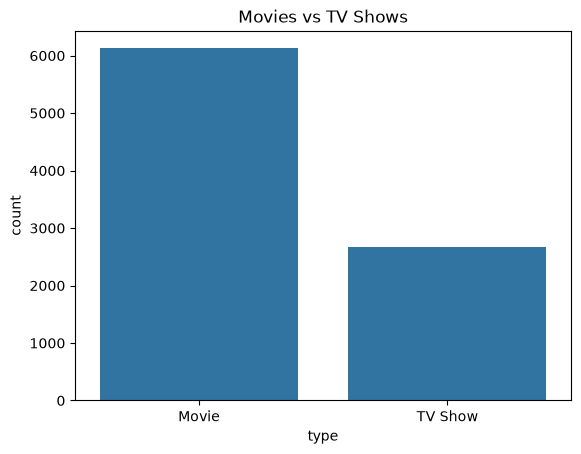

In [26]:
sns.countplot(data=df_clean, x="type")
plt.title("Movies vs TV Shows")
plt.show()

In [27]:
df_clean["type"].value_counts()

type
Movie      6124
TV Show    2663
Name: count, dtype: int64

### 7.1 Graph for Rating Distribution

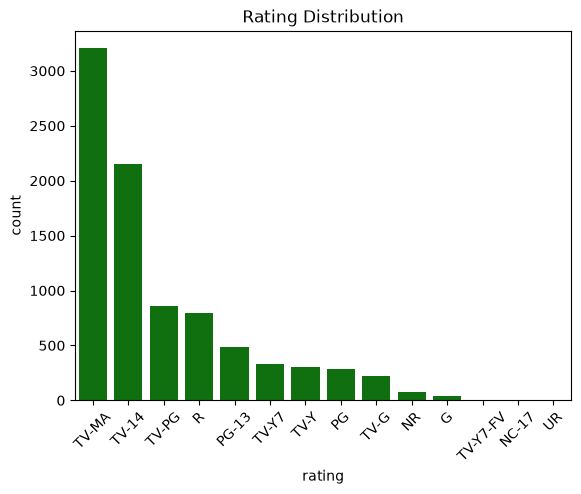

In [28]:
sns.countplot(data=df_clean, x="rating", order=df_clean["rating"].value_counts().index, color = 'green')
plt.title("Rating Distribution")
plt.xticks(rotation=45)
plt.show()

In [29]:
genres = df_clean["listed_in"].str.split(", ").explode()
top_genres = genres.value_counts().head(10)

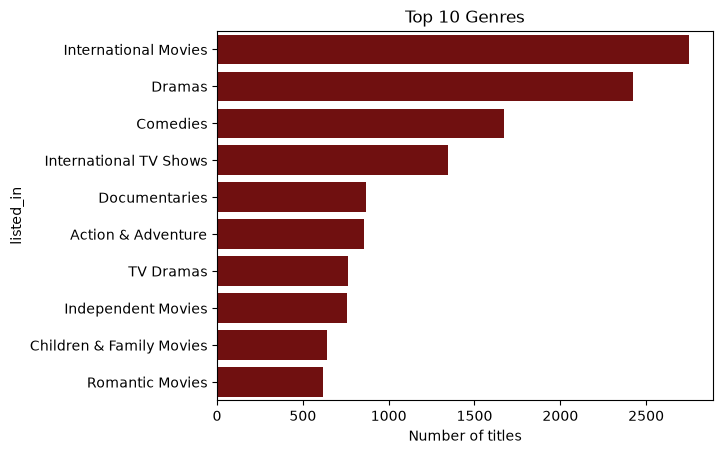

In [30]:
sns.barplot(x=top_genres.values, y=top_genres.index, color = 'maroon')
plt.title("Top 10 Genres")
plt.xlabel("Number of titles")
plt.show()

### 7.2 Converting Text to Numbers (TF-IDF)

In [31]:
tfidf = TfidfVectorizer(token_pattern=r"\S+")
tfidf_matrix = tfidf.fit_transform(df_clean["combined"])

In [32]:
tfidf_matrix.shape

(8787, 5130)

## 8. Now Using the Cosine Function

In [33]:
similarity = cosine_similarity(tfidf_matrix, tfidf_matrix)

In [34]:
similarity.shape

(8787, 8787)

In [35]:
similarity[0][:5]

array([1.        , 0.        , 0.01644757, 0.01068396, 0.03470125])

### 8.1 Generating Recommendations
I wrote a function that takes a title and returns the 5 most similar titles, using the similarity scores. Then I tested it on a few titles.


In [36]:
def recommend(title, n=5):
    index = df_clean[df_clean["title"] == title].index[0]
    scores = similarity[index]
    top = [i for i in scores.argsort()[::-1] if i != index][:n]
    result = df_clean.iloc[top][["title", "type", "listed_in"]].copy()
    result["score"] = scores[top].round(2)
    return result

### 8.2 Testing the Recommendation with Different Titles

In [37]:
recommend("Ganglands")

,title,type,listed_in,score
8405,Crime Time,TV Show,"Crime TV Shows, International TV Shows, TV Act...",0.86
6735,Lupin,TV Show,"Crime TV Shows, International TV Shows, TV Act...",0.86
575,Fatal Destiny,TV Show,"Crime TV Shows, International TV Shows, TV Act...",0.79
8331,Agent Raghav,TV Show,"Crime TV Shows, International TV Shows, TV Act...",0.78
7969,Smoking,TV Show,"Crime TV Shows, International TV Shows, TV Act...",0.78


In [38]:
recommend("Zindagi Gulzar Hai")

,title,type,listed_in,score
487,In Laws,TV Show,"International TV Shows, Romantic TV Shows, TV ...",1.00
369,Cinta Iris,TV Show,"International TV Shows, Romantic TV Shows, TV ...",1.00
8493,Humsafar,TV Show,"International TV Shows, Romantic TV Shows, TV ...",1.00
261,Dérè: An African Tale,TV Show,"International TV Shows, Romantic TV Shows, TV ...",1.00
542,Behind the Newsroom,TV Show,"International TV Shows, Romantic TV Shows, TV ...",0.96


In [39]:
recommend("Zak Storm")

,title,type,listed_in,score
7858,Spy Kids: Mission Critical,TV Show,Kids' TV,1.0
6618,Fast & Furious Spy Racers,TV Show,Kids' TV,1.0
6749,The Adventures of Sonic the Hedgehog,TV Show,Kids' TV,1.0
8740,The Super Mario Bros. Super Show!,TV Show,Kids' TV,1.0
8630,Power Rangers: Megaforce,TV Show,Kids' TV,1.0


In [40]:
recommend("Midnight Mass")

,title,type,listed_in,score
7073,Ratched,TV Show,"TV Dramas, TV Horror, TV Mysteries",0.90
7907,The Haunting of Hill House,TV Show,"TV Dramas, TV Horror, TV Mysteries",0.90
7043,The Haunting of Bly Manor,TV Show,"TV Dramas, TV Horror, TV Mysteries",0.90
6616,Brand New Cherry Flavor,TV Show,"TV Dramas, TV Horror, TV Mysteries",0.90
7959,The Originals,TV Show,"TV Dramas, TV Horror, TV Mysteries",0.89


In [ ]:
name = input("Enter a Netflix title: ")
name = name.strip().lower()

matches = df_clean[df_clean["title"].str.lower() == name]

if len(matches) == 0:
    close = df_clean[df_clean["title"].str.lower().str.contains(name, regex=False)]["title"].head(5).tolist()
    print("Title not found.")
    if close:
        print("Did you mean:", close)
else:
    display(recommend(matches.iloc[0]["title"]))

## 9. Evaluation

In [42]:
def quality(title, n=5):
    recs = recommend(title, n)
    row = df_clean[df_clean["title"] == title].iloc[0]
    original_genres = set(row["listed_in"].split(", "))
    genre_hits = 0
    for g in recs["listed_in"]:
        if original_genres & set(g.split(", ")):
            genre_hits += 1
    type_hits = (recs["type"] == row["type"]).sum()
    return genre_hits / n, type_hits / n

In [43]:
sample = df_clean["title"].sample(200, random_state=42)
results = [quality(t) for t in sample]
print("Share with at least one common genre:", np.mean([r[0] for r in results]))
print("Share with the same type:", np.mean([r[1] for r in results]))

Share with at least one common genre: 0.9840000000000001
Share with the same type: 0.9990000000000001


## 10. Conclusion

In this task I built a simple Netflix recommendation system. You type a title, and it gives back the 5 most similar titles.

First I checked the data. At the start it looked clean, but I found that missing values were hidden as the word "Not Given" in the director column (2,588 rows) and the country column (287 rows). I turned them into proper missing values and filled them with empty text, so I didn't lose any titles. I also removed 3 repeated rows.

Then I joined the type, genres, country, rating and director of every title into one line of text, converted it into numbers with TF-IDF, and used cosine similarity to find how close the titles are to each other.

To check the quality, I tested 200 random titles. About 98% of the recommendations shared at least one genre with the original title, and almost all of them (99.9%) were the same type, Movie or TV Show. I also noticed that the genres have the biggest effect on the results. Some titles with the same genres and country get the same score, so their order is not really meaningful.

These numbers are high mostly because the system is built on genres, so they show that it works as expected, not that every viewer would like the recommendations. A better version could use plot descriptions or what users actually watched. This dataset has neither, so I couldn't try that.